# 2. Compare covariance models

Separate PCA, joint PCA, and PLSSVD on the same recordings. These are descriptive, in-sample comparisons. Cluster computations are separate from notebook visualization.

In [21]:
from pathlib import Path
import sys
import json
import shlex
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
MEG_DIR = ROOT / 'MEG' / 'dataMEG'
IEEG_DIR = ROOT / 'ieeg_shortWOBS_fs250'
OUTPUT_DIR = ROOT / 'out' / 'covariance'
METADATA_CSV = None
PROJECT_PATH = None
MEG_KIND = 'paired_coverage'
BLOCK_SCALING = True
N_COMPONENTS = 10
CONDITION_MODE = 'average'
CORRECT_IEEG_X1000 = True
CORRECT_MEG_ZSCORE = True
CONDITIONS = [1, 2]
SFREQ = 250.
MEG_TMIN = None
SEED = 2026
MAX_GRAM_GIB = 2.
MODEL_STYLES = {'separate_pca': '-', 'joint_pca': '--', 'plssvd': ':'}

sys.path[:0] = [str(ROOT), str(ROOT.parent), str(ROOT.parent / 'LB')]
from vs2_run_cov_models import load_selected_datasets, load_models
from vs1_run_coverage import analysis_directory, SCHEMA_VERSION
from vs1_coverage_matching_utils import variance_summary
from vs1_coverage_figures import apply_style, MODALITY_COLORS
apply_style()


## Load the datasets

The preprocessing corrections precede model fitting. Whole-modality scaling is applied once during fitting, independently to each modality. Random subject association is reproducible from `SEED`.

In [22]:
INPUT_DIRS = {'meg': MEG_DIR, 'ieeg': IEEG_DIR}
CONFIG_OUTPUT_DIR = OUTPUT_DIR

CONFIG = dict(data=dict(meg_dir=str(INPUT_DIRS['meg']), ieeg_dir=str(INPUT_DIRS['ieeg']),
    metadata_csv=str(METADATA_CSV) if METADATA_CSV else None,
    project_path=str(PROJECT_PATH) if PROJECT_PATH else None,
    meg_coordinate_unit='m', ieeg_coordinate_unit='mm', meg_tmin=MEG_TMIN,
    meg_scaling='channel_zscore' if CORRECT_MEG_ZSCORE else 'none',
    ieeg_multiplier=1000. if CORRECT_IEEG_X1000 else 1., sfreq=SFREQ, conditions=CONDITIONS),
    output_dir=str(CONFIG_OUTPUT_DIR), meg_kind=MEG_KIND, block_scaling=BLOCK_SCALING,
    n_components=N_COMPONENTS, condition_mode=CONDITION_MODE, seed=SEED, max_gram_gib=MAX_GRAM_GIB)
ieeg, meg = load_selected_datasets(CONFIG)
display(variance_summary({'iEEG': ieeg, MEG_KIND: meg}))


,n_observations,n_features,total_variance,mean_feature_variance,constant_features,dense_float64_GiB
dataset,,,,,,
iEEG,1025,2576,140.009109,0.054351,0,0.019673
paired_coverage,1025,2576,1484.175299,0.576155,0,0.019673


## Fit the three models

| Model | Objective | Time courses used in matching |
|---|---|---|
| Separate PCA | Maximise each modality's own variance | `X Wx` and `Y Wy` from independent fits |
| Joint PCA | Maximise variance of `[X Y]` | Separate contributions `X Wx` and `Y Wy`; their sum is the joint score |
| PLSSVD | Maximise cross-covariance with unit-norm weights | `X Wx` and `Y Wy` from SVD of `X.T @ Y` |

All matrices are centred across observations. 

The helper uses exact sample-space decompositions, avoiding a huge source × electrode cross-covariance matrix for full MEG concatenation. Joint PCA is compared using its separate modality contributions, never by correlating its common score with itself.

In [23]:
INPUT_DIR = OUTPUT_DIR
CONFIG_FILE = INPUT_DIR / 'config.json'
RECOMPUTE = False

CONFIG_FILE.parent.mkdir(parents=True, exist_ok=True)
CONFIG_FILE.write_text(json.dumps(CONFIG, indent=2))
command = ['python', '-u', str(ROOT / 'vs2_run_cov_models.py'), '--config', str(CONFIG_FILE)]
if RECOMPUTE: command.append('--recompute')
print(shlex.join(command))
MODEL_DIR = analysis_directory(CONFIG, 'models')
marker = MODEL_DIR / 'RUN_COMPLETE.json'
models = None
if marker.exists() and not RECOMPUTE:
    if json.loads(marker.read_text()) != dict(CONFIG, schema_version=SCHEMA_VERSION):
        raise ValueError('Saved configuration differs; run the printed command.')
    models = load_models(MODEL_DIR)
else:
    print('Run the command, then set RECOMPUTE=False and rerun this cell.')


python -u /users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/vs2_run_cov_models.py --config /users/barbara/Desktop/MIB_iEEG/iEEGvsMEG/out/covariance/config.json


## Variance explained and shared cross-covariance

`evaluate_cov_models` reports, cumulatively for the first **k** components:

- **`ieeg_variance_explained` / `meg_variance_explained`:** `1 − reconstruction error / total centred signal variance`, with a separate denominator for each modality. Separate PCA and PLS reconstruct through their own weights. Joint PCA reconstructs each modality using the joint score and its corresponding weight block.
- **`shared_crosscov_fraction`:** the fraction of squared cross-covariance captured by the retained feature subspaces. It is `||Qx.T C Qy||² / ||C||²`, where `C = X.T Y/(n−1)` and Qx/Qy are orthonormal bases of the retained weight spaces. For PLSSVD this equals the retained squared singular values divided by all squared singular values.

The last measure is **cross-covariance energy, not a uniquely identified shared biological variance**. It must not be added to the two variance-explained fractions. It depends on preprocessing and can include shared stimulus timing and sampling noise.

Native score variances and paired cross-covariances are included as additional columns. These reproduce the decomposition used in `LB_Summary.ipynb`, with explicit centring and denominators.

Separate PCA is expected to maximise each modality’s reconstruction variance, and PLSSVD to maximise retained cross-covariance energy. Those advantages are consequences of their objectives, not independent evidence of a better model.

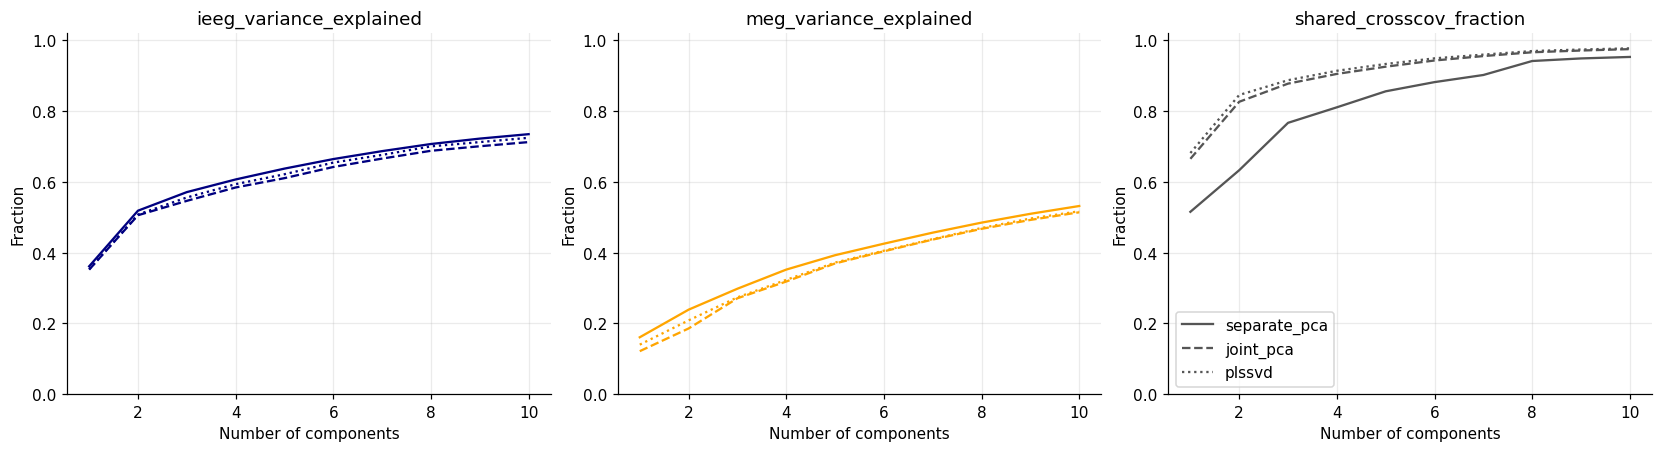

In [25]:
INPUT_DIR = MODEL_DIR
FIGSIZE = (15, 4)
# TODO ORGANISE THE OTHER WAY

if models is not None:
    variance = pd.read_csv(INPUT_DIR / 'variance.csv')
    #display(variance)
    fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, constrained_layout=True)
    metrics = ['ieeg_variance_explained', 'meg_variance_explained', 'shared_crosscov_fraction']
    for ax, metric, color in zip(axes, metrics, [MODALITY_COLORS['iEEG'], MODALITY_COLORS['MEG'], '#555555']):
        for name, group in variance.groupby('model', sort=False):
            ax.plot(group.k, group[metric], linestyle=MODEL_STYLES[name], color=color, label=name)
        ax.set(xlabel='Number of components', ylabel='Fraction', title=metric, ylim=(0, 1.02)); ax.grid(True)
    axes[-1].legend()
    plt.show()


## Time courses

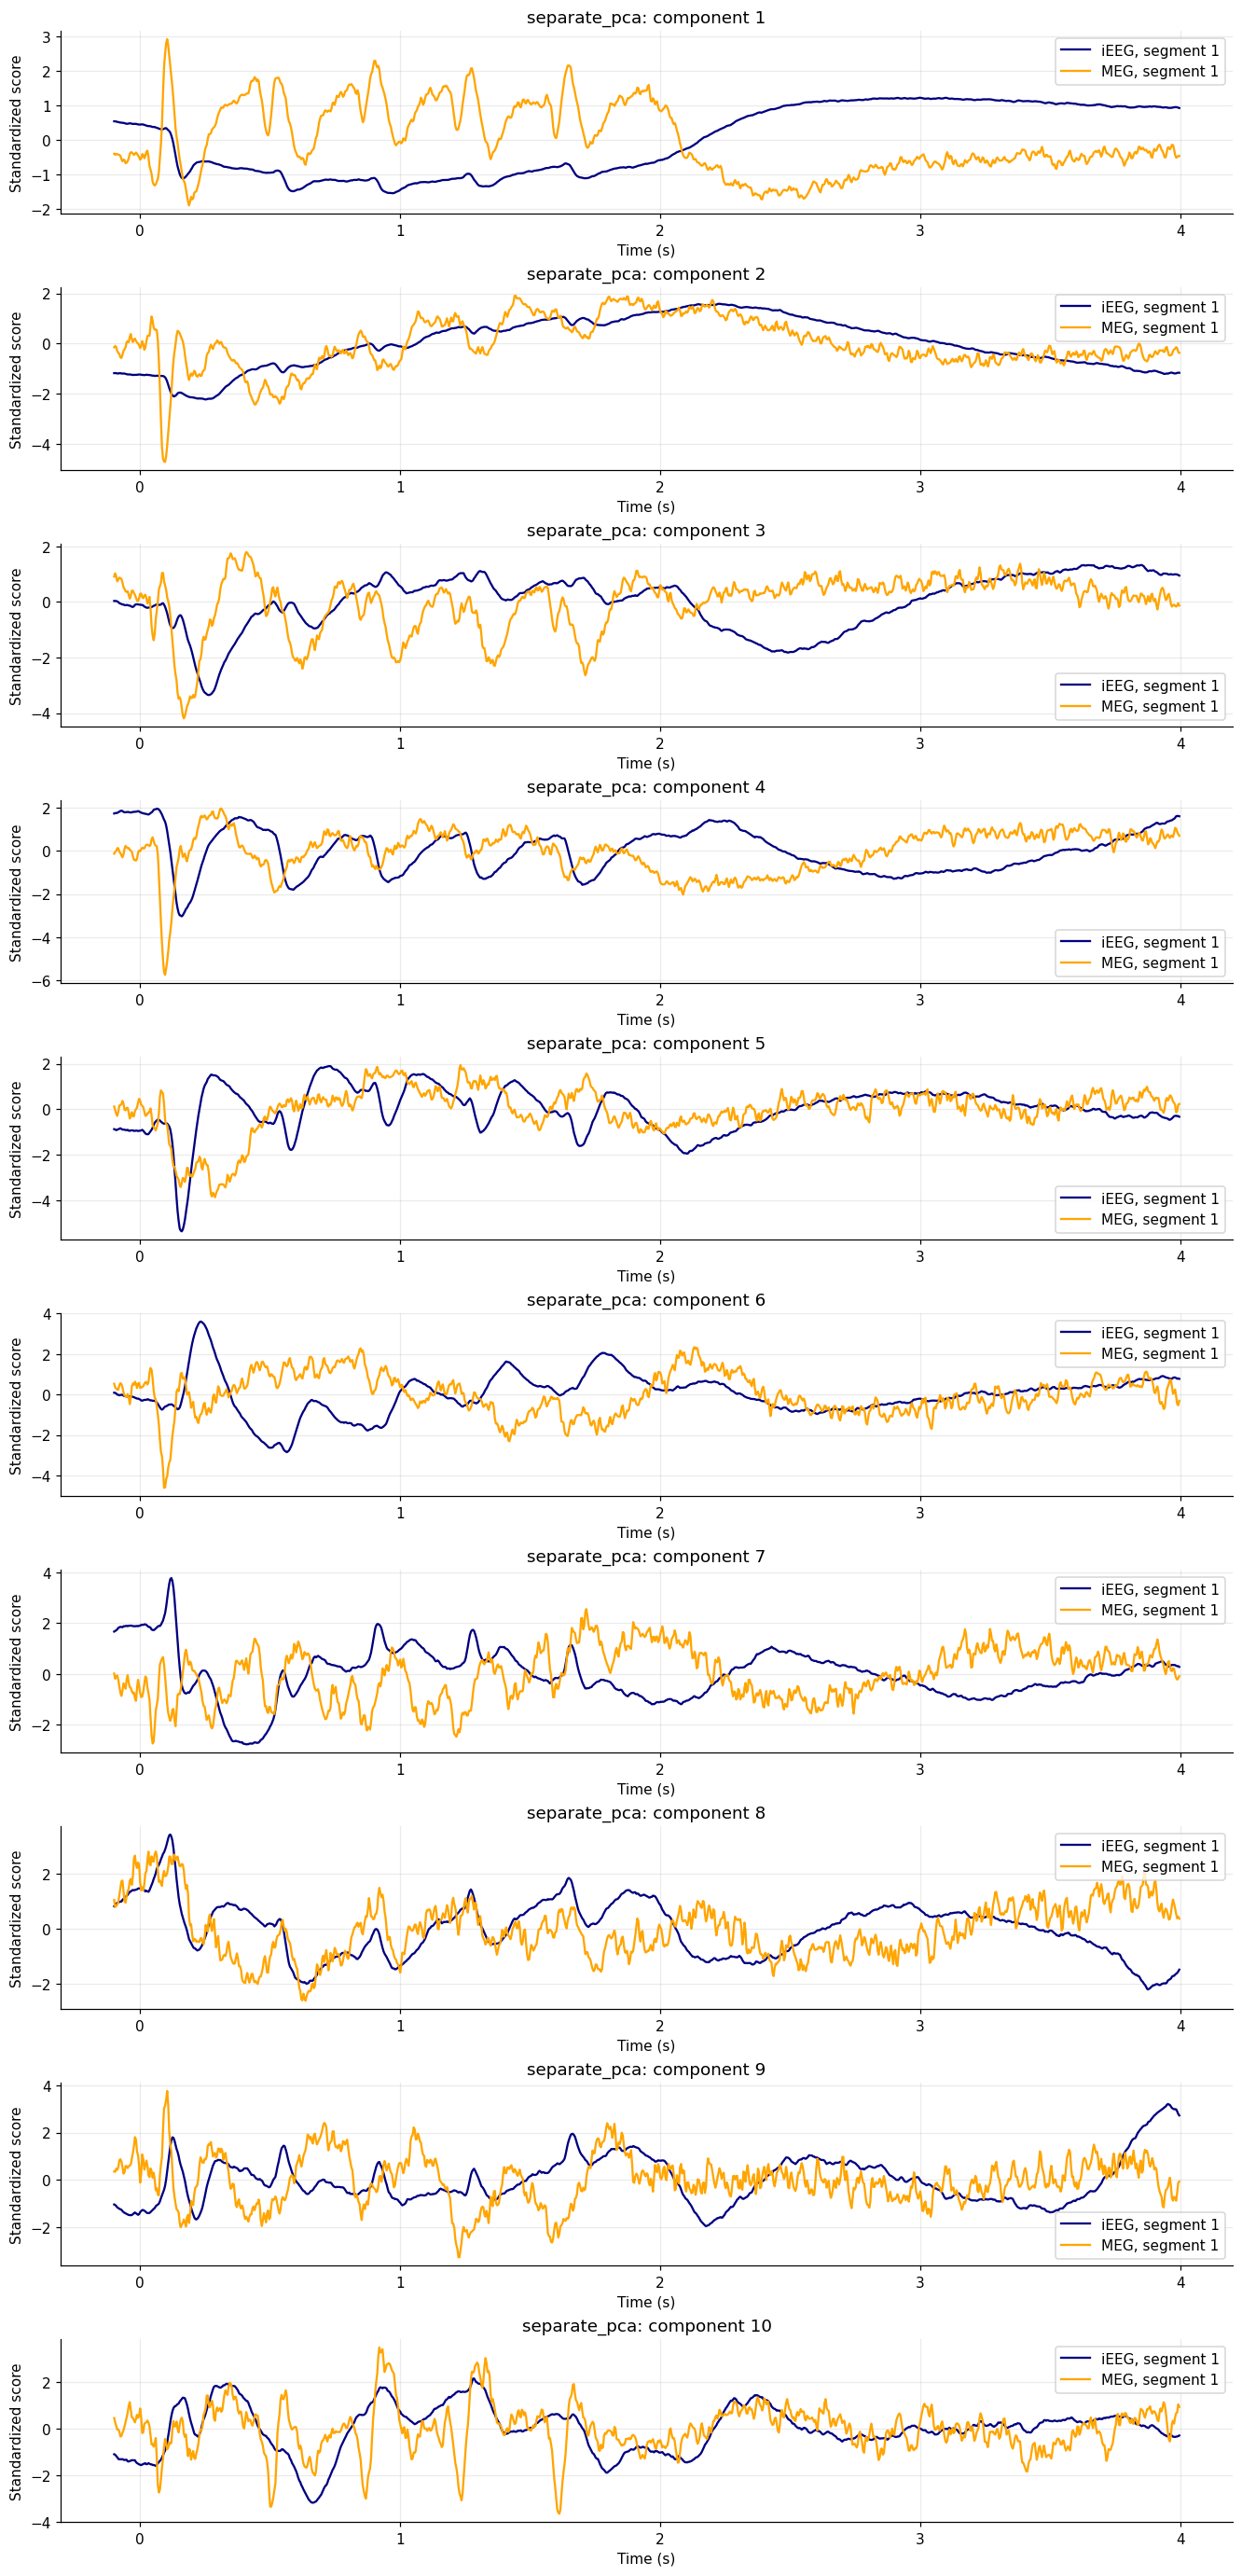

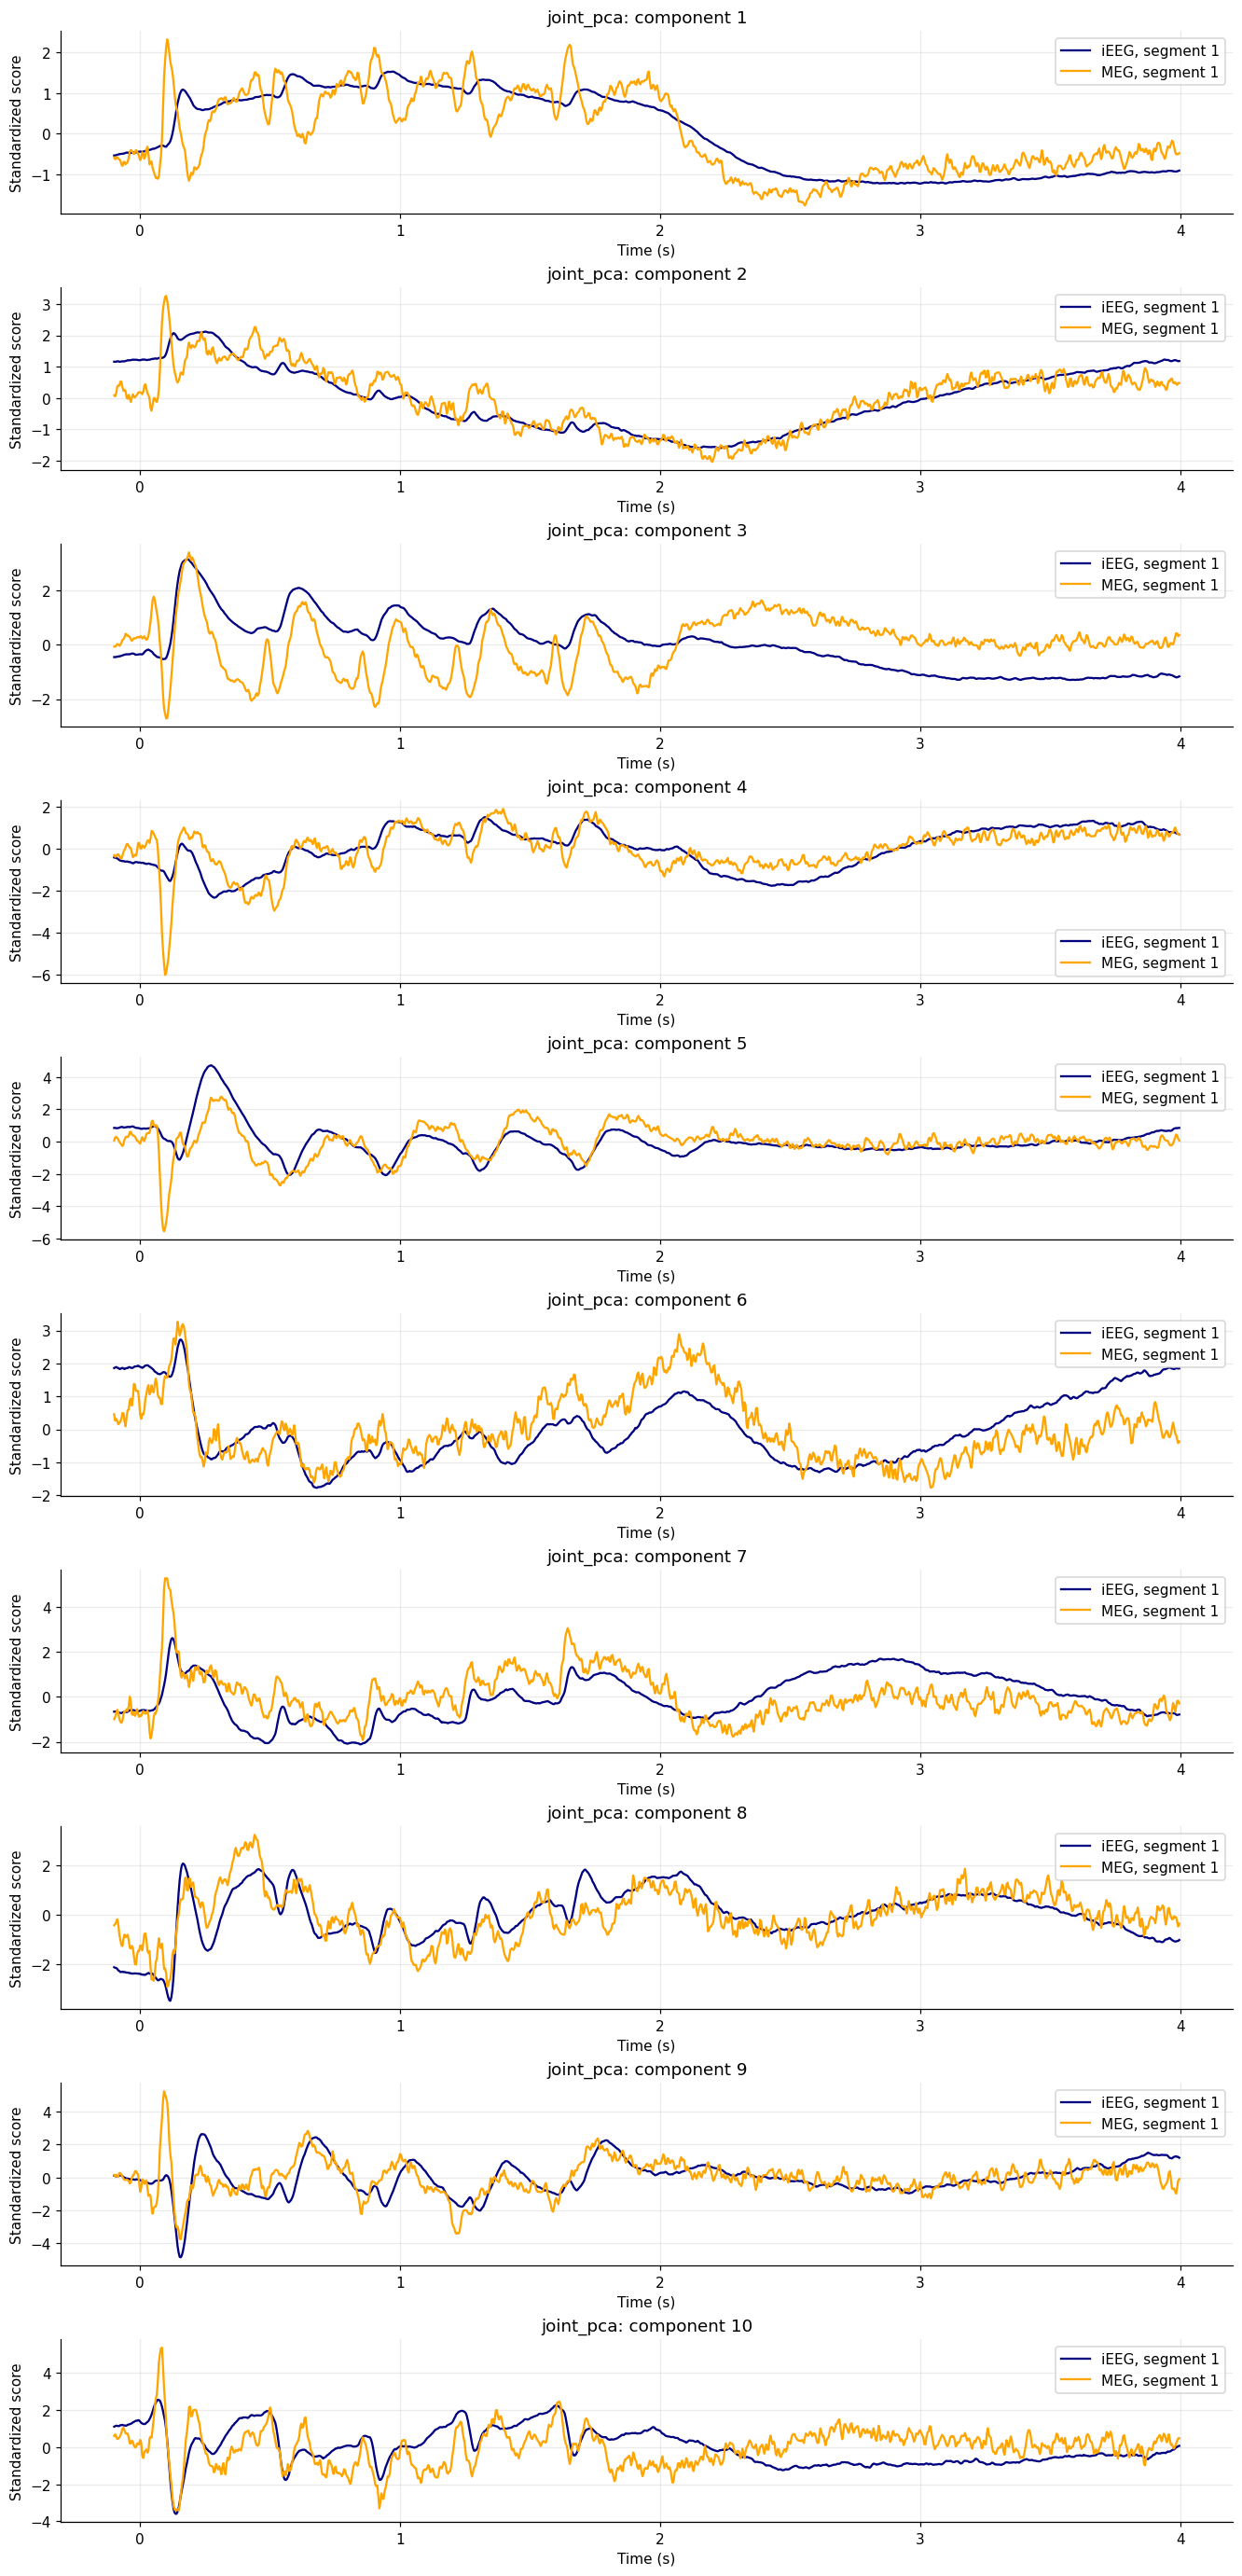

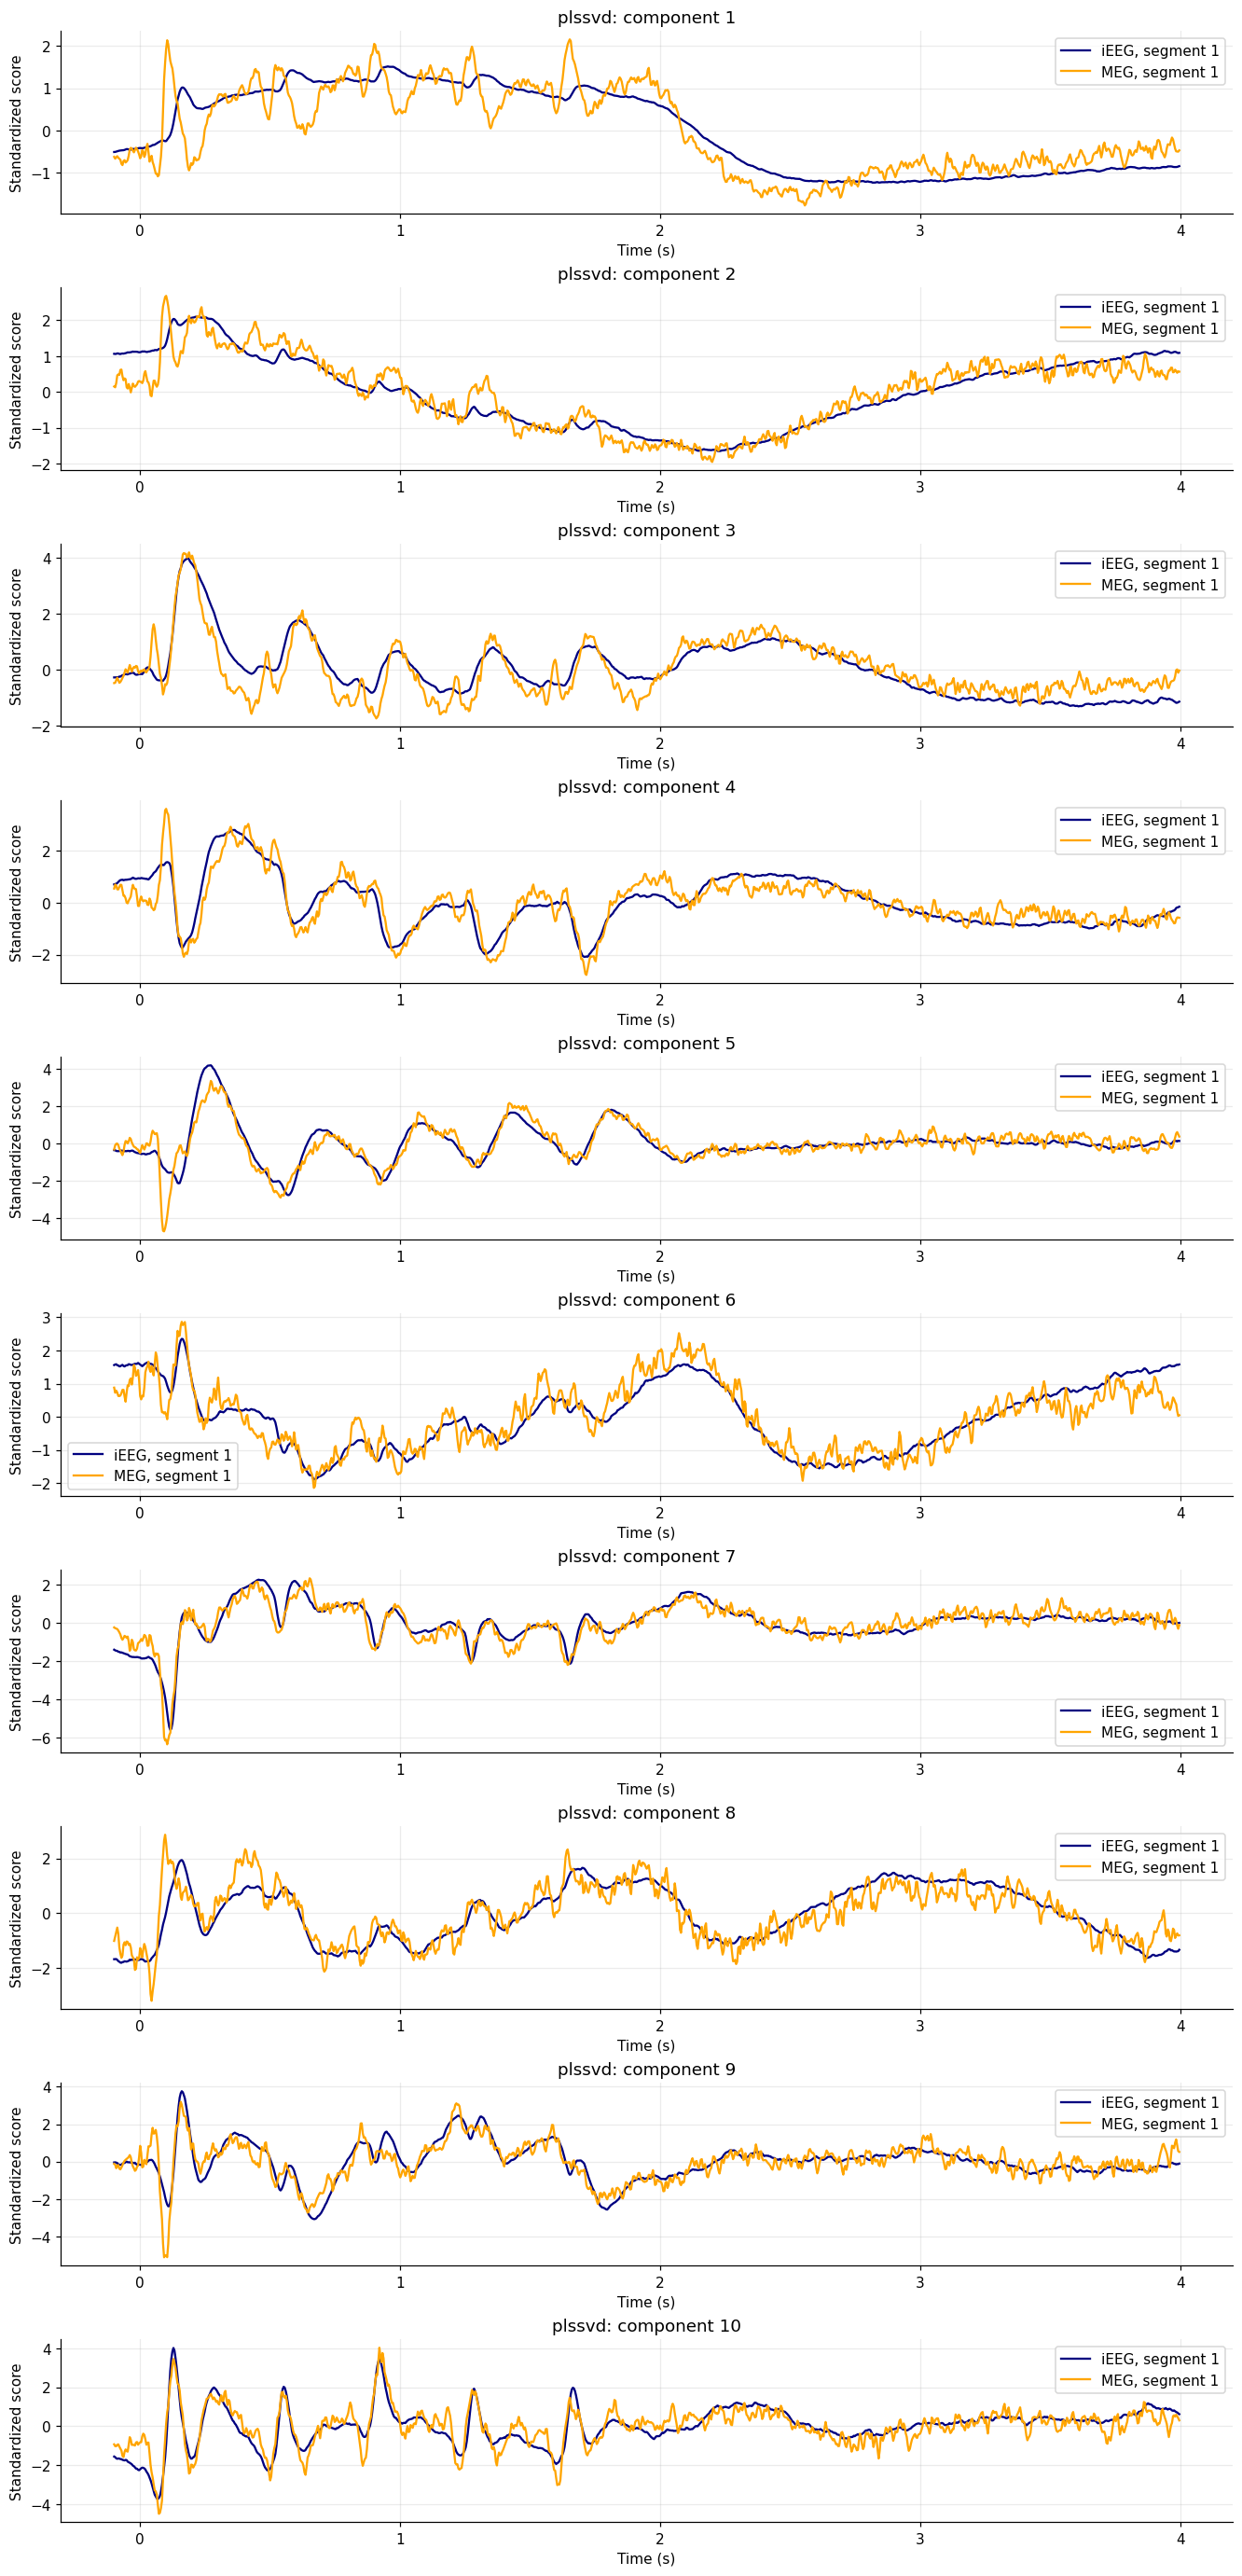

In [26]:
PLOT_COMPONENTS = N_COMPONENTS
STANDARDIZE_SCORES = True

if models is not None:
    for model in models.values():
        k = min(PLOT_COMPONENTS, model.ieeg_scores.shape[1])
        fig, axes = plt.subplots(k, 1, figsize=(12, 2.5*k), squeeze=False, constrained_layout=True)
        for pc, ax in enumerate(axes[:, 0]):
            for modality, values in [('iEEG', model.ieeg_scores), ('MEG', model.meg_scores)]:
                trace = values[:, pc]
                if STANDARDIZE_SCORES:
                    sd = trace.std(); trace = (trace-trace.mean())/(sd if sd > 0 else 1.)
                for condition, segment in enumerate(trace.reshape(-1, len(model.times))):
                    ax.plot(model.times, segment, color=MODALITY_COLORS[modality],
                            linestyle=['-', '--', ':', '-.'][condition % 4], label=f'{modality}, segment {condition+1}')
            ax.set(title=f'{model.name}: component {pc+1}', xlabel='Time (s)',
                   ylabel='Standardized score' if STANDARDIZE_SCORES else 'Score'); ax.grid(True); ax.legend()
        plt.show()


## Covariance structure

Heatmaps retain signed covariance. The componentwise line plot shows score variance in each modality and **2 |Cov(iEEG, MEG)|**. These three quantities do not in general sum to the variance of the summed scores.

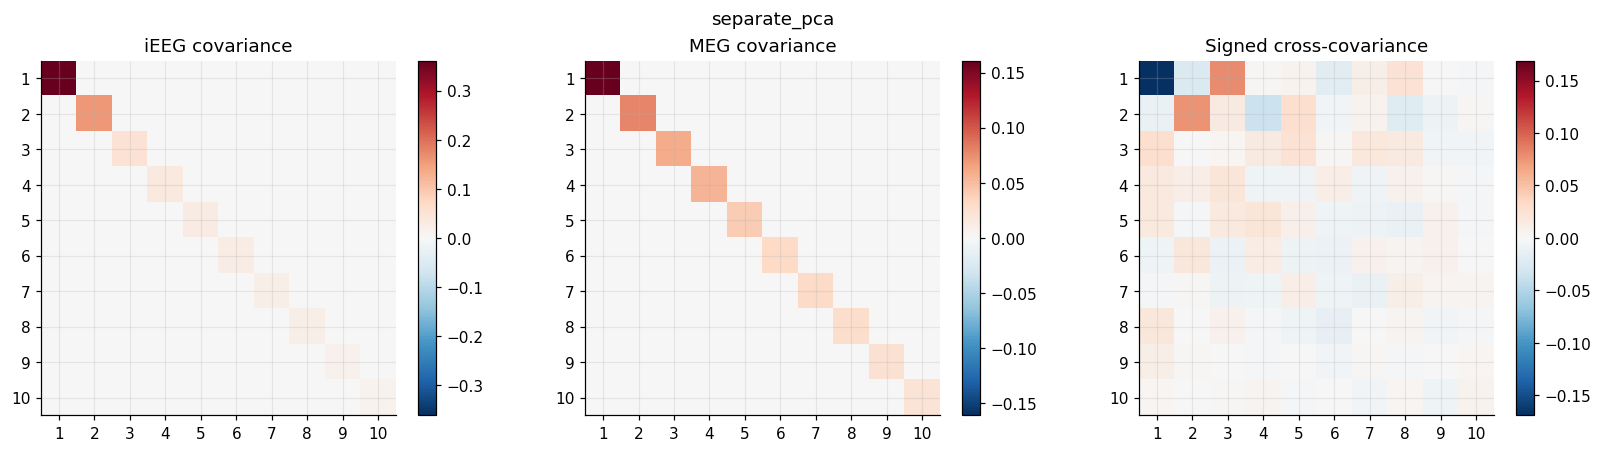

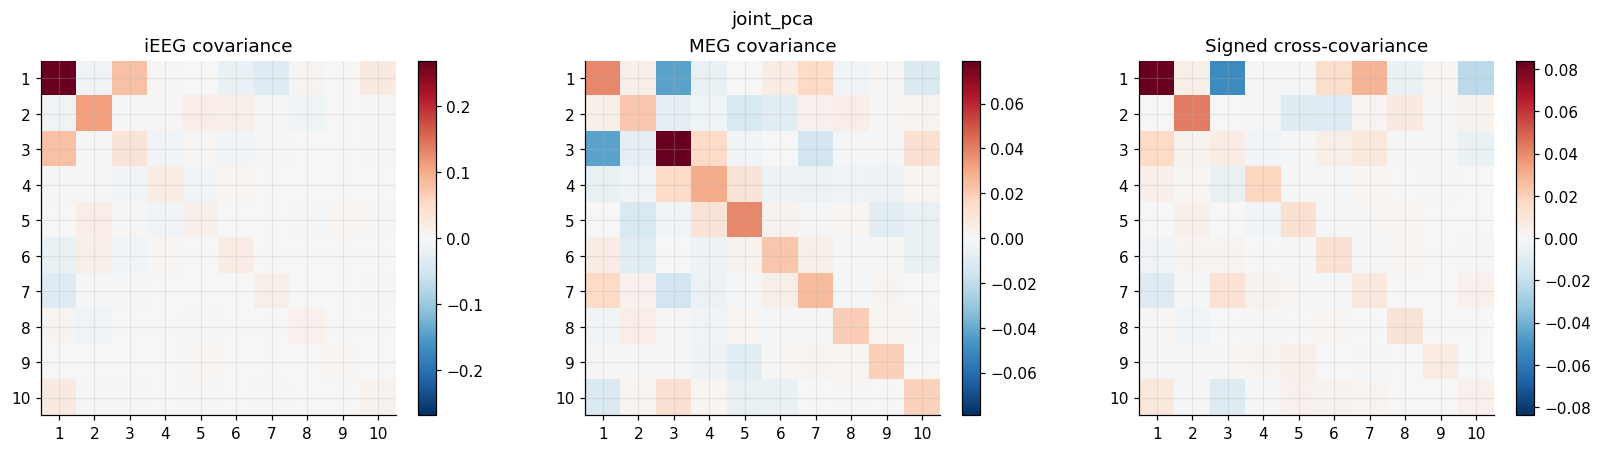

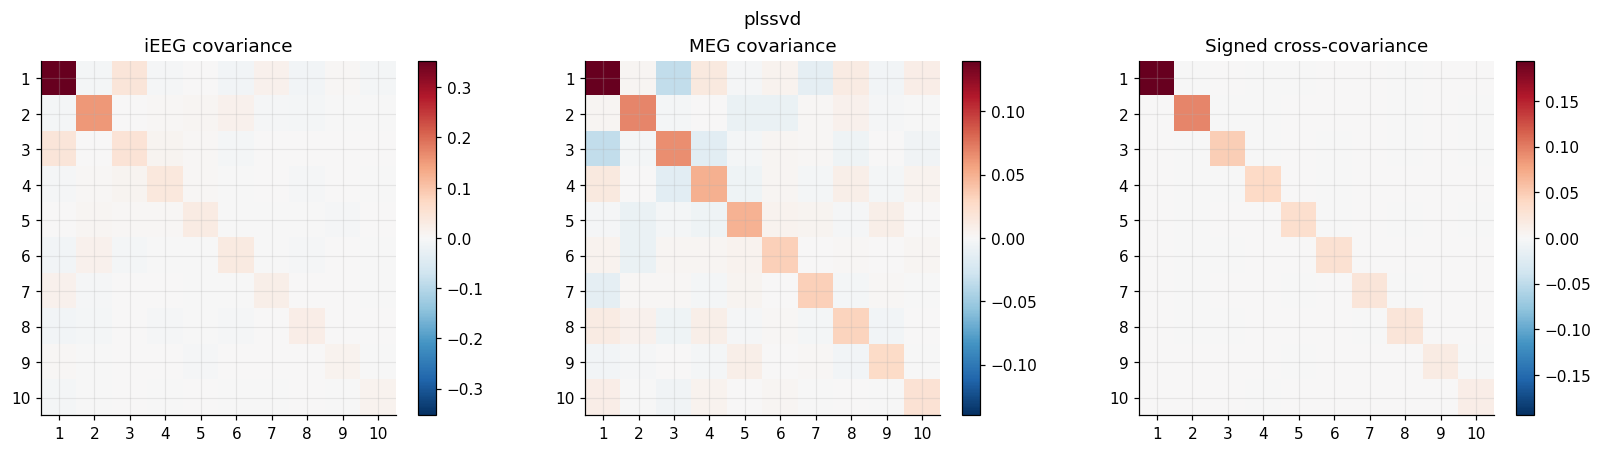

In [27]:
PLOT_COMPONENTS = N_COMPONENTS
COMMON_SCALE = False
FIGSIZE = (15, 4)

if models is not None:
    for model in models.values():
        k = min(PLOT_COMPONENTS, model.ieeg_scores.shape[1])
        x, y = model.ieeg_scores[:, :k], model.meg_scores[:, :k]
        x, y = x-x.mean(0), y-y.mean(0)
        matrices = [x.T@x/(len(x)-1), y.T@y/(len(x)-1), x.T@y/(len(x)-1)]
        limit = max(np.max(abs(matrix)) for matrix in matrices) or 1.
        fig, axes = plt.subplots(1, 3, figsize=FIGSIZE, constrained_layout=True)
        for ax, matrix, title in zip(axes, matrices, ['iEEG covariance', 'MEG covariance', 'Signed cross-covariance']):
            bound = limit if COMMON_SCALE else (np.max(abs(matrix)) or 1.)
            im = ax.imshow(matrix, cmap='RdBu_r', vmin=-bound, vmax=bound)
            ax.set(title=title, xticks=np.arange(k), xticklabels=np.arange(1,k+1),
                   yticks=np.arange(k), yticklabels=np.arange(1,k+1)); ax.grid(True)
            fig.colorbar(im, ax=ax)
        fig.suptitle(model.name); plt.show()


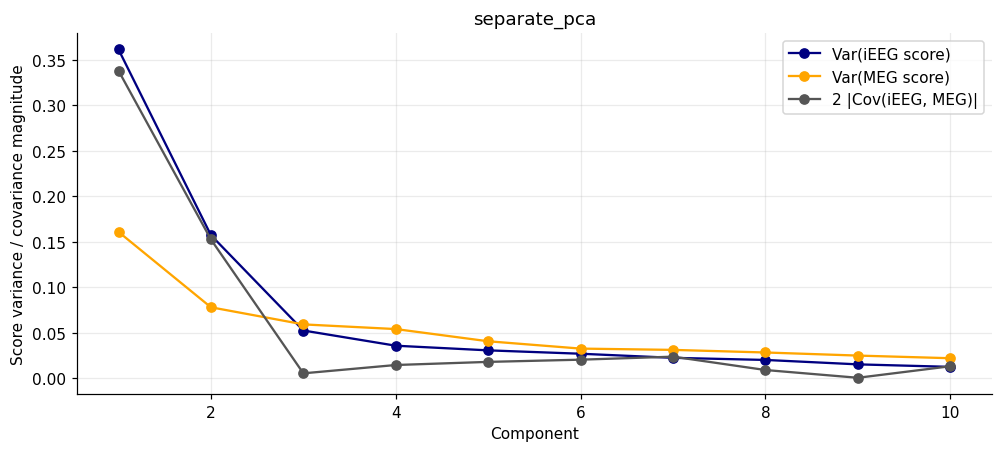

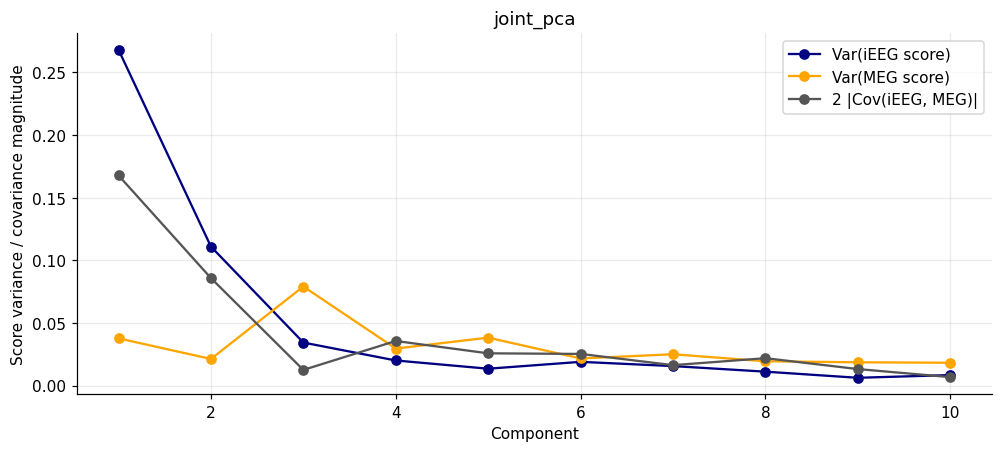

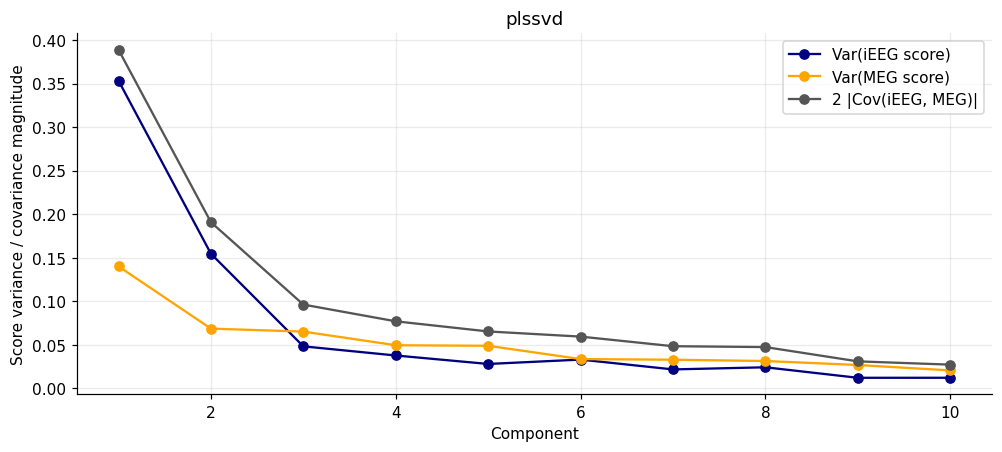

In [28]:
PLOT_COMPONENTS = N_COMPONENTS
FIGSIZE = (9, 4)

if models is not None:
    for model in models.values():
        k = min(PLOT_COMPONENTS, model.ieeg_scores.shape[1])
        x, y = model.ieeg_scores[:, :k], model.meg_scores[:, :k]
        cov = np.sum((x-x.mean(0))*(y-y.mean(0)), axis=0)/(len(x)-1)
        fig, ax = plt.subplots(figsize=FIGSIZE, constrained_layout=True)
        ax.plot(np.arange(1,k+1), np.var(x, axis=0, ddof=1), 'o-', color=MODALITY_COLORS['iEEG'], label='Var(iEEG score)')
        ax.plot(np.arange(1,k+1), np.var(y, axis=0, ddof=1), 'o-', color=MODALITY_COLORS['MEG'], label='Var(MEG score)')
        ax.plot(np.arange(1,k+1), 2*abs(cov), 'o-', color='#555555', label='2 |Cov(iEEG, MEG)|')
        ax.set(title=model.name, xlabel='Component', ylabel='Score variance / covariance magnitude'); ax.legend(); ax.grid(True)
        plt.show()


## Within-modality model similarity
**Subspace overlap** compares all retained patterns together and permits rotations/mixing of their axes. **Mean matched |r|** compares individual component pairs and averages their absolute Pearson correlations.

In [29]:
INPUT_DIR = MODEL_DIR
WITHIN_K = min(3, N_COMPONENTS)

within_models = None
if models is not None:
    within_models = {name: pd.read_csv(INPUT_DIR / f'{name}.csv') for name in
        ['within_model_metrics', 'within_model_pairs', 'within_model_correlations']}
    display(within_models['within_model_metrics'].query('k == @WITHIN_K'))


,modality,model_a,model_b,k,repeat,space,partition,overlap,rank_a,rank_b,angles_deg,n_valid_pairs,matched_signed_r,matched_abs_r
12,ieeg,separate_pca,joint_pca,3,0,temporal_scores,in_sample,0.881054,3,3,"[0.15616802745144379, 1.3152532775969323, 36.6...",3,0.811767,0.811767
13,ieeg,separate_pca,joint_pca,3,0,spatial_patterns,in_sample,0.918937,3,3,"[0.034917495403524894, 0.574103585308857, 29.5...",3,0.914722,0.914722
14,ieeg,separate_pca,plssvd,3,0,temporal_scores,in_sample,0.890240,3,3,"[0.8001999087682345, 3.763151093497795, 34.742...",3,0.917804,0.917804
15,ieeg,separate_pca,plssvd,3,0,spatial_patterns,in_sample,0.926090,3,3,"[0.17494319724527013, 1.661379882013257, 28.03...",3,0.953982,0.953982
16,ieeg,joint_pca,plssvd,3,0,temporal_scores,in_sample,0.992913,3,3,"[0.48393453734393355, 2.070710769935103, 8.106...",3,0.938865,0.938865
17,ieeg,joint_pca,plssvd,3,0,spatial_patterns,in_sample,0.996068,3,3,"[0.13073184959883524, 0.8544727213464669, 6.17...",3,0.975087,0.975087
72,meg,separate_pca,joint_pca,3,0,temporal_scores,in_sample,0.927667,3,3,"[1.9017936123383559, 15.914316062526577, 22.03...",3,0.767232,0.767232
73,meg,separate_pca,joint_pca,3,0,spatial_patterns,in_sample,0.953888,3,3,"[0.879160550797632, 12.464747195187924, 17.608...",3,0.831407,0.831407
74,meg,separate_pca,plssvd,3,0,temporal_scores,in_sample,0.840470,3,3,"[3.949943075072951, 24.17349088728215, 33.5944...",3,0.837215,0.837215
75,meg,separate_pca,plssvd,3,0,spatial_patterns,in_sample,0.886768,3,3,"[1.7372034203115638, 18.878758958031543, 28.93...",3,0.883457,0.883457


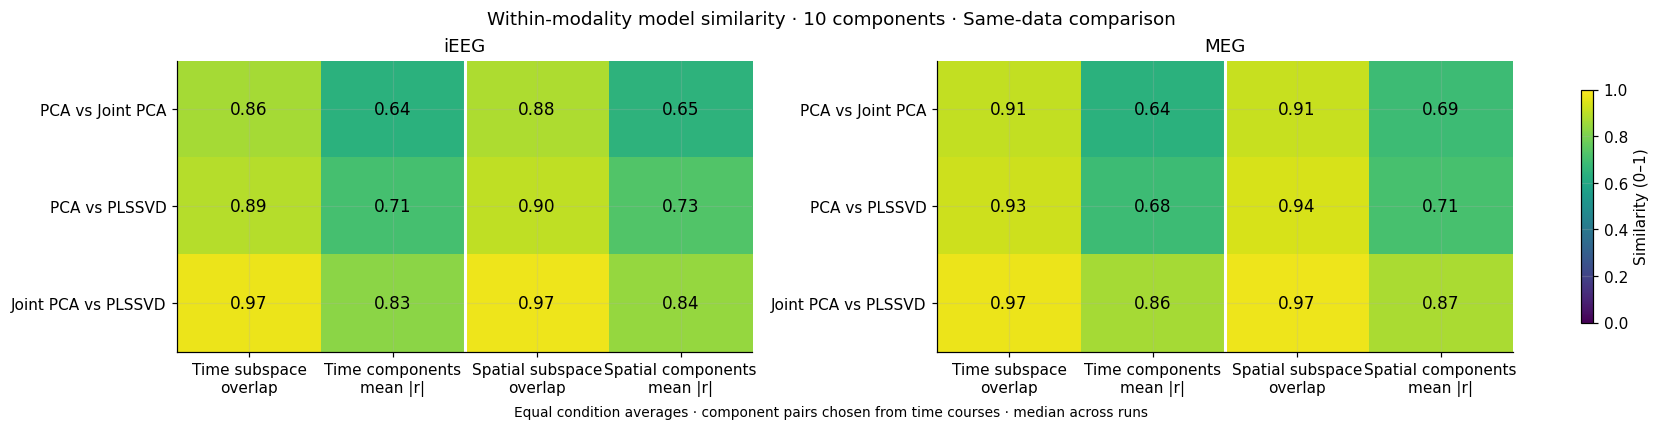

In [33]:
result = within_models
k = WITHIN_K
partition = 'in_sample'

if within_models is not None:
    import matplotlib.pyplot as plt
    table = result['within_model_metrics']
    table = table[(table.k == k) & (table.partition == partition)]
    if table.empty:
        raise ValueError('No results for this dimension/partition.')
    modalities = [m for m in ('ieeg','meg') if m in set(table.modality)]
    labels = {'separate_pca':'PCA', 'plssvd':'PLSSVD', 'joint_pca':'Joint PCA'}
    columns = [(space,metric) for space in ('temporal_scores','spatial_patterns')
               for metric in ('overlap','matched_abs_r')]
    fig, axes = plt.subplots(1,len(modalities),figsize=(15,3.8),squeeze=False,layout='constrained')
    for ax, modality in zip(axes.flat,modalities):
        sub = table[table.modality == modality]
        pairs = list(sub[['model_a','model_b']].drop_duplicates().itertuples(index=False,name=None))
        matrix = np.full((len(pairs),len(columns)),np.nan)
        for i,(a,b) in enumerate(pairs):
            for j,(space,metric) in enumerate(columns):
                values = sub[(sub.model_a==a)&(sub.model_b==b)&(sub.space==space)][metric]
                matrix[i,j] = values.median()
        im = ax.imshow(np.ma.masked_invalid(matrix),vmin=0,vmax=1,cmap='viridis',aspect='auto')
        ax.set(title='iEEG' if modality=='ieeg' else 'MEG',
               xticks=range(4),xticklabels=['Time subspace\noverlap','Time components\nmean |r|','Spatial subspace\noverlap','Spatial components\nmean |r|'],
               yticks=range(len(pairs)),yticklabels=[labels.get(a,a)+' vs '+labels.get(b,b) for a,b in pairs])
        ax.axvline(1.5,color='white',lw=2)
        for i in range(len(pairs)):
            for j in range(4):
                v = matrix[i,j]
                ax.text(j,i,f'{v:.2f}' if np.isfinite(v) else '—',ha='center',va='center',
                        color='black' if v>.55 else 'white',fontsize=11)
    fig.colorbar(im,ax=axes.ravel().tolist(),label='Similarity (0–1)',shrink=.8)
    setting = 'Same-data comparison' if partition=='in_sample' else partition
    fig.suptitle(f'Within-modality model similarity · {k} components · {setting}')
    fig.supxlabel('Equal condition averages · component pairs chosen from time courses · median across runs',fontsize=9)
    for ax in fig.axes: ax.grid(True)
    plt.show()

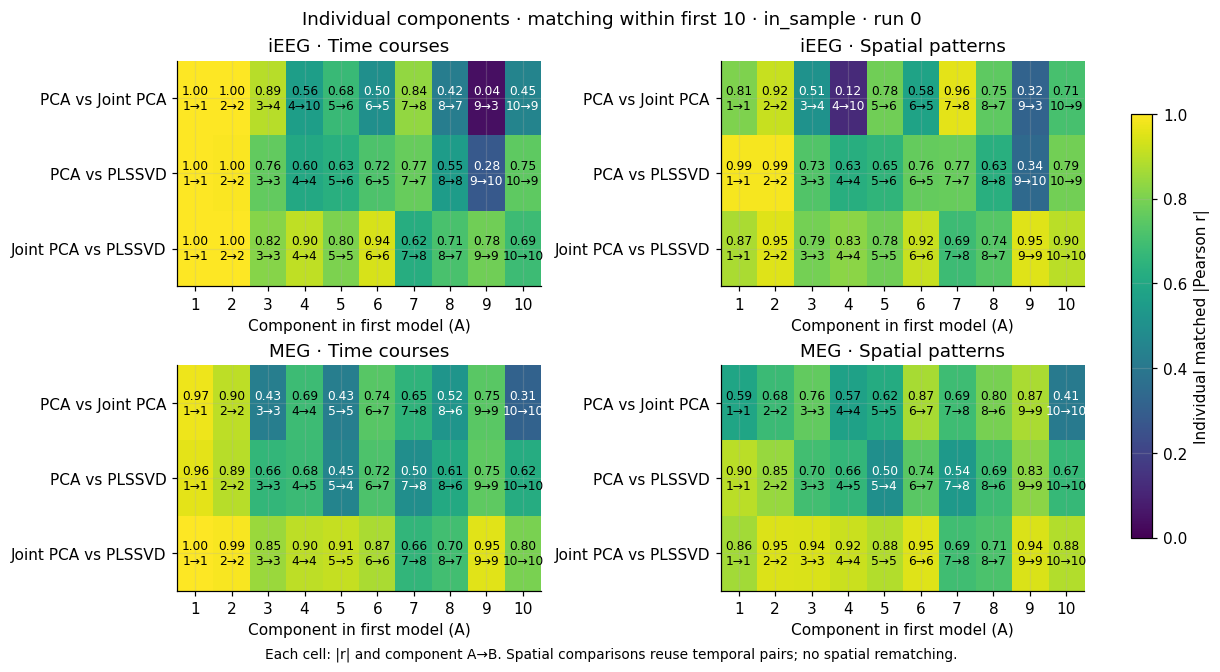

In [34]:
result = within_models
k = N_COMPONENTS
partition = 'in_sample'

if within_models is not None:
    import matplotlib.pyplot as plt
    corr = result['within_model_correlations']
    corr = corr[(corr.k == k) & (corr.partition == partition)]
    if corr.empty:
        raise ValueError('No component correlations for this dimension/partition.')
    repeat = corr.repeat.min()
    corr = corr[corr.repeat == repeat]
    pairs = result['within_model_pairs']
    pairs = pairs[(pairs.k == k) & (pairs.repeat == repeat) & pairs.valid_training_pair]
    keys = ['modality','model_a','model_b','k','repeat','component_a','component_b']
    matched = corr.merge(pairs[keys], on=keys, validate='many_to_one')
    labels = {'separate_pca':'PCA','joint_pca':'Joint PCA','plssvd':'PLSSVD'}
    fig, axes = plt.subplots(2,2,figsize=(max(11,k*1.05),6),layout='constrained')
    for row,modality in enumerate(('ieeg','meg')):
        sub = corr[corr.modality == modality]
        model_pairs = list(sub[['model_a','model_b']].drop_duplicates().itertuples(index=False,name=None))
        for col,space in enumerate(('temporal_scores','spatial_patterns')):
            ax = axes[row,col]
            matrix = np.full((len(model_pairs),k),np.nan)
            annotations = {}
            for i,(a,b) in enumerate(model_pairs):
                records = matched[(matched.modality==modality)&(matched.model_a==a)&(matched.model_b==b)&(matched.space==space)]
                for record in records.itertuples():
                    j = int(record.component_a)-1
                    matrix[i,j] = abs(record.signed_r)
                    annotations[i,j] = f'{abs(record.signed_r):.2f}\n{record.component_a}→{record.component_b}'
            im = ax.imshow(np.ma.masked_invalid(matrix),cmap='viridis',vmin=0,vmax=1,aspect='auto')
            ax.set(title=f'{"iEEG" if modality=="ieeg" else "MEG"} · {"Time courses" if col==0 else "Spatial patterns"}',
                   xticks=range(k),xticklabels=range(1,k+1),xlabel='Component in first model (A)',
                   yticks=range(len(model_pairs)),yticklabels=[f'{labels.get(a,a)} vs {labels.get(b,b)}' for a,b in model_pairs])
            for i in range(len(model_pairs)):
                for j in range(k):
                    ax.text(j,i,annotations.get((i,j),'—'),ha='center',va='center',fontsize=8,
                            color='black' if matrix[i,j]>.55 else 'white')
    fig.colorbar(im,ax=axes.ravel().tolist(),label='Individual matched |Pearson r|',shrink=.8)
    fig.suptitle(f'Individual components · matching within first {k} · {partition} · run {repeat}')
    fig.supxlabel('Each cell: |r| and component A→B. Spatial comparisons reuse temporal pairs; no spatial rematching.',fontsize=9)
    for ax in fig.axes: ax.grid(True)
    plt.show()